In [1]:
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from dataset import get_federated_dataloaders
from models import FraudMLP
from utils import calculate_entropy, compute_dynamic_mu
from client import train_client_dp, train_client_nodp
from server import federated_averaging, evaluate_model

In [2]:
def set_seed(seed=123):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(123)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# ==============================================================================
# CELL 1: SETUP & FEDSHIELD MATHEMATICS
# ==============================================================================
num_clients = 5
client_loaders, test_loader = get_federated_dataloaders(filepath="data/creditcard.csv", num_clients=num_clients, alpha=0.1)

print("\n--- Exact Class Distribution per Bank ---")
entropies = []
sample_counts = [] # NEW: Required for standard FedAvg/FedProx weighting

for i, loader in enumerate(client_loaders):
    all_labels = []
    for _, labels in loader:
        all_labels.extend(labels.tolist())
    
    normal_count = all_labels.count(0)
    fraud_count = all_labels.count(1)
    total_cases = normal_count + fraud_count
    fraud_percent = (fraud_count / total_cases) * 100 if total_cases > 0 else 0
    
    print(f"Bank {i+1} | Normal: {normal_count} | Fraud: {fraud_count} ({fraud_percent:.4f}%)")
    
    sample_counts.append(total_cases) # NEW: Store the volume of data for each bank
    entropies.append(calculate_entropy(np.array(all_labels), num_classes=2))

# Calculate Dynamic Parameters
dynamic_mus = compute_dynamic_mu(entropies, num_classes=2, mu_base=0.01, lambda_scale=0.5)
fedshield_weights = [np.exp(e) for e in entropies]

print("\n--- FedShield Dynamic Variables ---")
for i in range(num_clients):
    print(f"Bank {i+1} | Entropy: {entropies[i]:.4f} | mu_k: {dynamic_mus[i]:.4f} | Exp Weight: {fedshield_weights[i]:.4f}")

Loading and preparing federated partitions...

--- Exact Class Distribution per Bank ---
Bank 1 | Normal: 20029 | Fraud: 364 (1.7849%)
Bank 2 | Normal: 45 | Fraud: 0 (0.0000%)
Bank 3 | Normal: 41 | Fraud: 28 (40.5797%)
Bank 4 | Normal: 1086 | Fraud: 0 (0.0000%)
Bank 5 | Normal: 206250 | Fraud: 2 (0.0010%)

--- FedShield Dynamic Variables ---
Bank 1 | Entropy: 0.1292 | mu_k: 0.0144 | Exp Weight: 1.1379
Bank 2 | Entropy: -0.0000 | mu_k: 0.0150 | Exp Weight: 1.0000
Bank 3 | Entropy: 0.9742 | mu_k: 0.0101 | Exp Weight: 2.6492
Bank 4 | Entropy: -0.0000 | mu_k: 0.0150 | Exp Weight: 1.0000
Bank 5 | Entropy: 0.0002 | mu_k: 0.0150 | Exp Weight: 1.0002


In [4]:
fedshield_weights_v2 = [np.sqrt(n) * np.exp(e) for e, n in zip(entropies, sample_counts)]

print("--- FedShieldFull2 Hybrid Weights ---")
for i in range(num_clients):
    print(f"Client {i+1} | sqrt(n) * exp(H): {fedshield_weights_v2[i]:.4f}")

--- FedShieldFull2 Hybrid Weights ---
Client 1 | sqrt(n) * exp(H): 162.4974
Client 2 | sqrt(n) * exp(H): 6.7082
Client 3 | sqrt(n) * exp(H): 22.0055
Client 4 | sqrt(n) * exp(H): 32.9545
Client 5 | sqrt(n) * exp(H): 454.2295


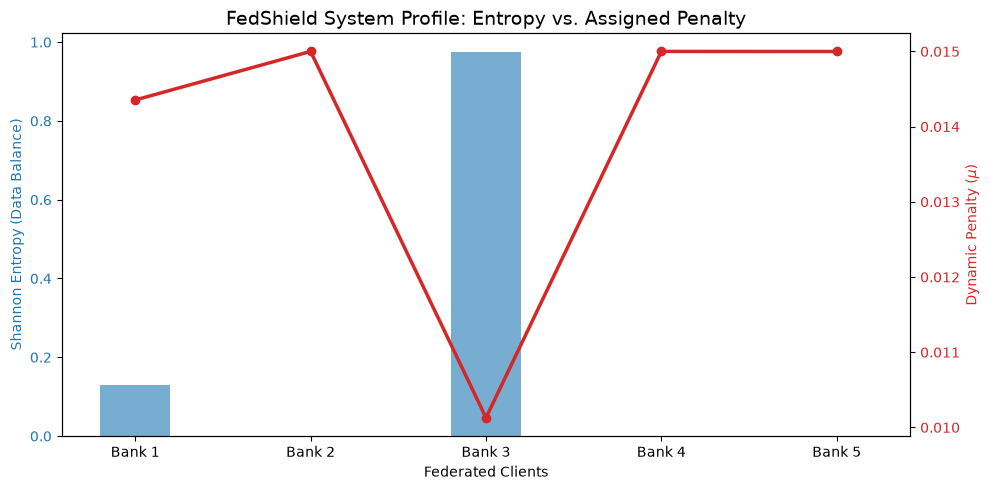

In [5]:
# VISUALIZATION 1: Entropy vs Dynamic Mu (System Profiling)
fig, ax1 = plt.subplots(figsize=(10, 5))

banks = [f"Bank {i+1}" for i in range(num_clients)]
color1 = 'tab:blue'
ax1.set_xlabel('Federated Clients')
ax1.set_ylabel('Shannon Entropy (Data Balance)', color=color1)
bars = ax1.bar(banks, entropies, color=color1, alpha=0.6, width=0.4, label="Entropy")
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()  
color2 = 'tab:red'
ax2.set_ylabel('Dynamic Penalty ($\mu$)', color=color2)
lines = ax2.plot(banks, dynamic_mus, color=color2, marker='o', linewidth=2.5, label="Assigned $\mu$")
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("FedShield System Profile: Entropy vs. Assigned Penalty", fontsize=14)
fig.tight_layout()
plt.show()

In [6]:
# ==============================================================================
# CELL 2: DP EXPERIMENT (PHASE 2)
# ==============================================================================
'''
def run_dp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n--- Starting {strategy} (DP Enabled) ---")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    
    for round_num in range(num_rounds):
        print(f"\n[Round {round_num + 1}/{num_rounds}]")
        client_models = []
        
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            local_model = copy.deepcopy(global_model)
            
            trained_model, loss, eps = train_client_dp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            print(f"  -> Bank {i+1} | Loss: {loss:.4f} | Eps: {eps:.2f}")
            
        if strategy == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
            
        # Unpack all 5 metrics
        pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device)
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1} | ROC-AUC: {roc_auc:.4f}")
        
        # Store final round metrics
        if round_num == num_rounds - 1:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    return roc_auc_history
'''
def run_dp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n========== STARTING DP PHASE: {strategy} ==========")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    final_labels, final_preds = [], []
    
    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            
            local_model = copy.deepcopy(global_model)
            
            trained_model, loss, eps = train_client_dp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        # Server Aggregation Logic Update
        if strategy == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        elif strategy == "FedShieldFull2":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights_v2)
        else: # FedAvg, FedProx, FedShield_Local all route here for n_k / N
            global_model = federated_averaging(global_model, client_models, weights=sample_counts) 
            
        # Grab the raw predictions only on the final round
        if is_final_round:
            pr_auc, roc_auc, acc, prec, rec, all_labels, all_preds = evaluate_model(global_model, test_loader, device, return_preds=True)
            final_labels, final_preds = all_labels, all_preds
        else:
            pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device, return_preds=False)
            
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1:02d}/{num_rounds:02d} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
        
        if is_final_round:
            final_acc, final_prec, final_rec = acc, prec, rec

    print(f"\n✅ FINAL {strategy} DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Acc: {final_acc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    
    # Print the full report and plot the matrix
    print(f"\n--- {strategy} (DP) Classification Report ---")
    print(classification_report(final_labels, final_preds, target_names=["Normal", "Fraud"], digits=4))
    
    cm = confusion_matrix(final_labels, final_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
    disp.plot(cmap=plt.cm.Blues, values_format='d')
    plt.title(f"{strategy} DP Confusion Matrix")
    plt.show()
    
    return roc_auc_history


========== STARTING DP PHASE: FedAvg ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0511 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0508 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0526 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0527 | PR-AUC: 0.0009

✅ FINAL FedAvg DP RESULTS -> ROC-AUC: 0.0527 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedAvg (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

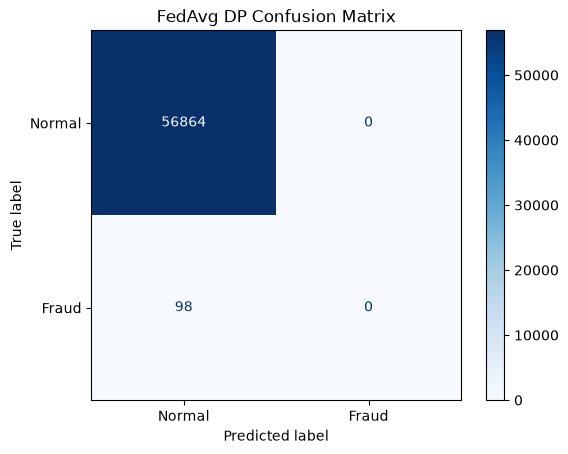

In [7]:
auc_fedavg_dp = run_dp_experiment("FedAvg", 15)


========== STARTING DP PHASE: FedProx ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0593 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0599 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0614 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0613 | PR-AUC: 0.0009

✅ FINAL FedProx DP RESULTS -> ROC-AUC: 0.0613 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedProx (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

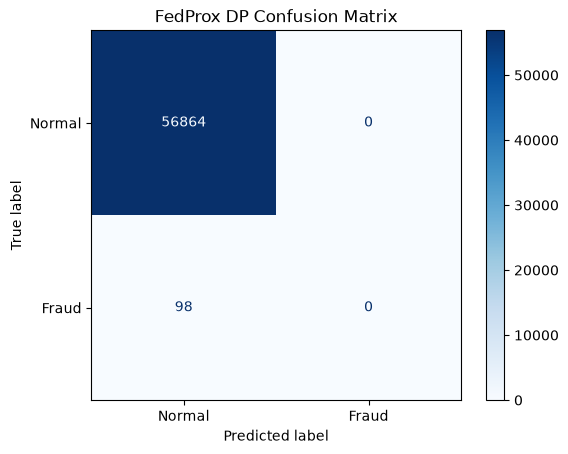

In [8]:
auc_fedprox_dp = run_dp_experiment("FedProx", 15)


========== STARTING DP PHASE: FedShield ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0873 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0804 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0741 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0744 | PR-AUC: 0.0009

✅ FINAL FedShield DP RESULTS -> ROC-AUC: 0.0744 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedShield (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

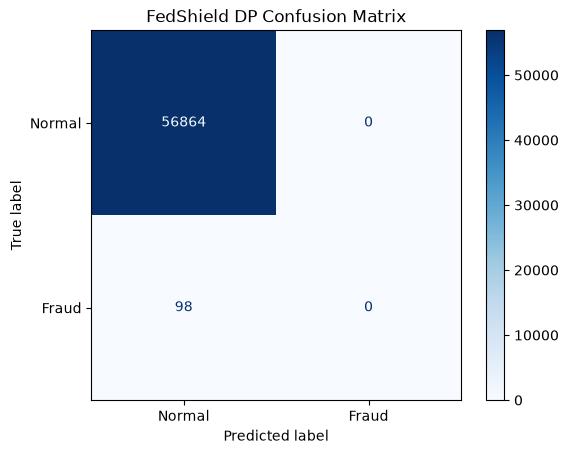

In [9]:
auc_fedshield_dp = run_dp_experiment("FedShield", 15)


========== STARTING DP PHASE: FedShieldFull2 ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0648 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0635 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0668 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0670 | PR-AUC: 0.0009

✅ FINAL FedShieldFull2 DP RESULTS -> ROC-AUC: 0.0670 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedShieldFull2 (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

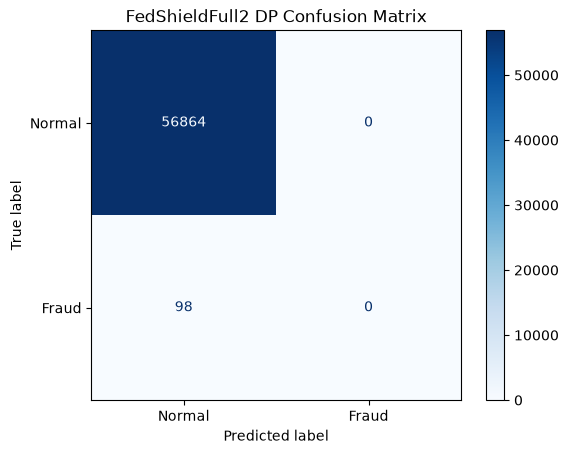

In [10]:
auc_fedshield2_dp = run_dp_experiment("FedShieldFull2", 15)

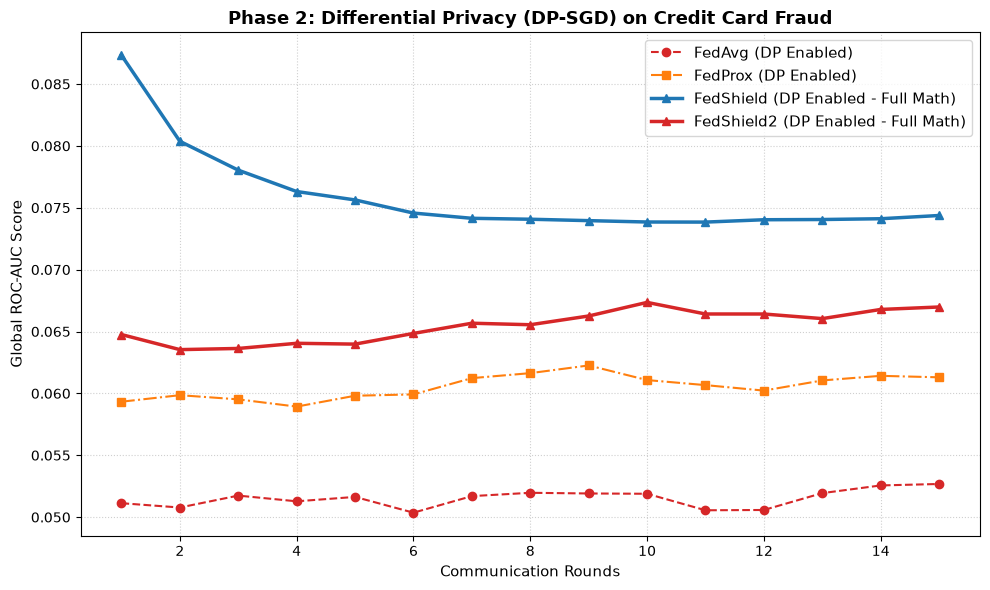

In [12]:
# ==============================================================================
# CELL 2.5: PLOT DP EXPERIMENT RESULTS
# ==============================================================================
plt.figure(figsize=(10, 6))
rounds = range(1, 16) 

plt.plot(rounds, auc_fedavg_dp, marker='o', linestyle='--', color='tab:red', label='FedAvg (DP Enabled)')
plt.plot(rounds, auc_fedprox_dp, marker='s', linestyle='-.', color='tab:orange', label='FedProx (DP Enabled)')
plt.plot(rounds, auc_fedshield_dp, marker='^', linestyle='-', color='tab:blue', linewidth=2.5, label='FedShield (DP Enabled - Full Math)')
plt.plot(rounds, auc_fedshield2_dp, marker='^', linestyle='-', color='tab:red', linewidth=2.5, label='FedShield2 (DP Enabled - Full Math)')

plt.title("Phase 2: Differential Privacy (DP-SGD) on Credit Card Fraud", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global ROC-AUC Score", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [13]:
# ==============================================================================
# CELL 3: NON-DP ABLATION STUDY (PHASE 3)
# ==============================================================================
'''
def run_nodp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n--- Starting {strategy} (NO DP - Ablation Study) ---")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    
    for round_num in range(num_rounds):
        client_models = []
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            local_model = copy.deepcopy(global_model)
            
            trained_model, _, _ = train_client_nodp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        # FORCE weights=None FOR ALL TO ISOLATE CLIENT-SIDE PENALTY
        global_model = federated_averaging(global_model, client_models, weights=None)
        
        # Unpack all 5 metrics
        pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device)
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1} | ROC-AUC: {roc_auc:.4f}")
        
        # Store final round metrics
        if round_num == num_rounds - 1:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} NO-DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    return roc_auc_history
'''
def run_nodp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {strategy} ==========")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    final_labels, final_preds = [], []
    
    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        
        for i in range(num_clients):
            if strategy == "FedAvg":
                current_mu = 0.0
            elif strategy == "FedProx":
                current_mu = 0.01
            else:
                current_mu = dynamic_mus[i]
                
            local_model = copy.deepcopy(global_model)
            
            trained_model, _, _ = train_client_nodp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        
        # Server Aggregation Logic Update
        if strategy == "FedShield_Full":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        elif strategy == "FedShieldFull2":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights_v2)
        else: # FedAvg, FedProx, FedShield_Local all route here for n_k / N
            global_model = federated_averaging(global_model, client_models, weights=sample_counts)
        
        if is_final_round:
            pr_auc, roc_auc, acc, prec, rec, all_labels, all_preds = evaluate_model(global_model, test_loader, device, return_preds=True)
            final_labels, final_preds = all_labels, all_preds
        else:
            pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device, return_preds=False)
            
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1:02d}/{num_rounds:02d} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
        
        if is_final_round:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} NO-DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Acc: {final_acc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    
    print(f"\n--- {strategy} (No-DP) Classification Report ---")
    print(classification_report(final_labels, final_preds, target_names=["Normal", "Fraud"], digits=4))
    
    cm = confusion_matrix(final_labels, final_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
    disp.plot(cmap=plt.cm.Greens, values_format='d') 
    plt.title(f"{strategy} No-DP Confusion Matrix")
    plt.show()
    
    return roc_auc_history


========== STARTING NON-DP PHASE: FedAvg ==========
Round 01/15 | ROC-AUC: 0.0583 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.0620 | PR-AUC: 0.0010
Round 03/15 | ROC-AUC: 0.0668 | PR-AUC: 0.0010
Round 04/15 | ROC-AUC: 0.0738 | PR-AUC: 0.0010
Round 05/15 | ROC-AUC: 0.0863 | PR-AUC: 0.0010
Round 06/15 | ROC-AUC: 0.1106 | PR-AUC: 0.0010
Round 07/15 | ROC-AUC: 0.1554 | PR-AUC: 0.0010
Round 08/15 | ROC-AUC: 0.2340 | PR-AUC: 0.0011
Round 09/15 | ROC-AUC: 0.3353 | PR-AUC: 0.0017
Round 10/15 | ROC-AUC: 0.4380 | PR-AUC: 0.0169
Round 11/15 | ROC-AUC: 0.5601 | PR-AUC: 0.0775
Round 12/15 | ROC-AUC: 0.6827 | PR-AUC: 0.1523
Round 13/15 | ROC-AUC: 0.7819 | PR-AUC: 0.2329
Round 14/15 | ROC-AUC: 0.8359 | PR-AUC: 0.3592
Round 15/15 | ROC-AUC: 0.8616 | PR-AUC: 0.4325

✅ FINAL FedAvg NO-DP RESULTS -> ROC-AUC: 0.8616 | PR-AUC: 0.4325 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedAvg (No-DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

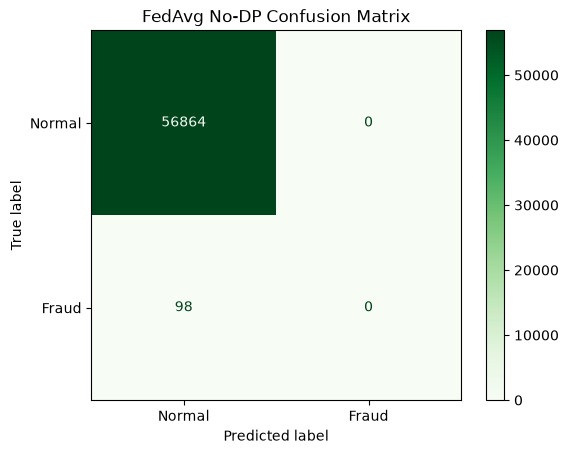

In [14]:
auc_fedavg_nodp = run_nodp_experiment("FedAvg", 15)


========== STARTING NON-DP PHASE: FedProx ==========
Round 01/15 | ROC-AUC: 0.0619 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.0682 | PR-AUC: 0.0009
Round 03/15 | ROC-AUC: 0.0807 | PR-AUC: 0.0009
Round 04/15 | ROC-AUC: 0.1039 | PR-AUC: 0.0009
Round 05/15 | ROC-AUC: 0.1402 | PR-AUC: 0.0009
Round 06/15 | ROC-AUC: 0.1955 | PR-AUC: 0.0010
Round 07/15 | ROC-AUC: 0.2705 | PR-AUC: 0.0014
Round 08/15 | ROC-AUC: 0.3629 | PR-AUC: 0.0050
Round 09/15 | ROC-AUC: 0.4723 | PR-AUC: 0.0293
Round 10/15 | ROC-AUC: 0.5898 | PR-AUC: 0.1101
Round 11/15 | ROC-AUC: 0.6761 | PR-AUC: 0.2104
Round 12/15 | ROC-AUC: 0.7303 | PR-AUC: 0.3192
Round 13/15 | ROC-AUC: 0.7690 | PR-AUC: 0.3810
Round 14/15 | ROC-AUC: 0.7963 | PR-AUC: 0.4183
Round 15/15 | ROC-AUC: 0.8156 | PR-AUC: 0.4571

✅ FINAL FedProx NO-DP RESULTS -> ROC-AUC: 0.8156 | PR-AUC: 0.4571 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedProx (No-DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

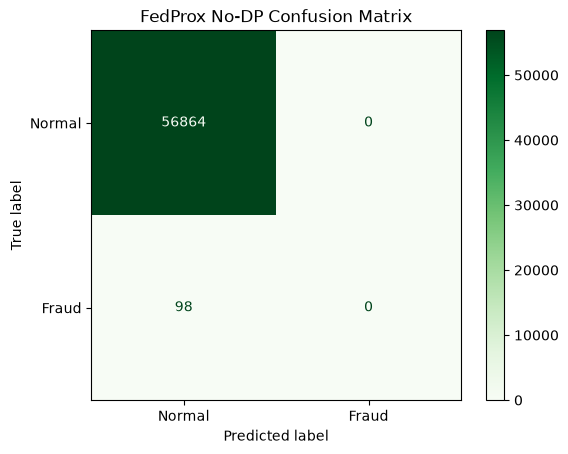

In [15]:
auc_fedprox_nodp = run_nodp_experiment("FedProx", 15)


========== STARTING NON-DP PHASE: FedShield_Local ==========
Round 01/15 | ROC-AUC: 0.0685 | PR-AUC: 0.0010
Round 02/15 | ROC-AUC: 0.0765 | PR-AUC: 0.0011
Round 03/15 | ROC-AUC: 0.0907 | PR-AUC: 0.0012
Round 04/15 | ROC-AUC: 0.1160 | PR-AUC: 0.0014
Round 05/15 | ROC-AUC: 0.1563 | PR-AUC: 0.0016
Round 06/15 | ROC-AUC: 0.2176 | PR-AUC: 0.0021
Round 07/15 | ROC-AUC: 0.3046 | PR-AUC: 0.0079
Round 08/15 | ROC-AUC: 0.4112 | PR-AUC: 0.0257
Round 09/15 | ROC-AUC: 0.5410 | PR-AUC: 0.1182
Round 10/15 | ROC-AUC: 0.6517 | PR-AUC: 0.2368
Round 11/15 | ROC-AUC: 0.7039 | PR-AUC: 0.4370
Round 12/15 | ROC-AUC: 0.7344 | PR-AUC: 0.5080
Round 13/15 | ROC-AUC: 0.7628 | PR-AUC: 0.5054
Round 14/15 | ROC-AUC: 0.7862 | PR-AUC: 0.5358
Round 15/15 | ROC-AUC: 0.8160 | PR-AUC: 0.5564

✅ FINAL FedShield_Local NO-DP RESULTS -> ROC-AUC: 0.8160 | PR-AUC: 0.5564 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedShield_Local (No-DP) Classification Report ---
              precision    recall  f1-score   su

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

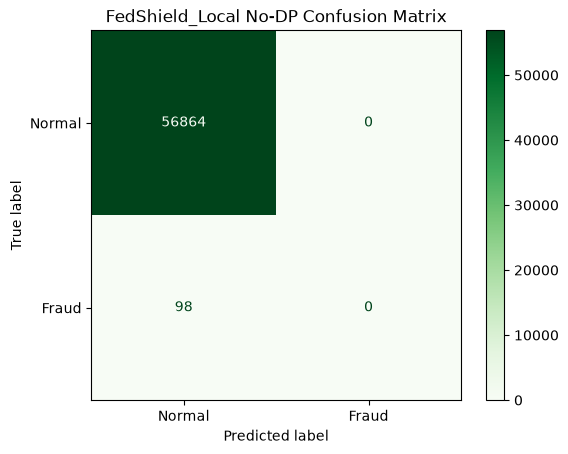

In [16]:
auc_fedshield_nodp = run_nodp_experiment("FedShield_Local", 15)


========== STARTING NON-DP PHASE: FedShield_Full ==========
Round 01/15 | ROC-AUC: 0.2356 | PR-AUC: 0.0038
Round 02/15 | ROC-AUC: 0.1318 | PR-AUC: 0.0019
Round 03/15 | ROC-AUC: 0.1476 | PR-AUC: 0.0065
Round 04/15 | ROC-AUC: 0.2075 | PR-AUC: 0.0215
Round 05/15 | ROC-AUC: 0.4169 | PR-AUC: 0.0696
Round 06/15 | ROC-AUC: 0.6170 | PR-AUC: 0.1926
Round 07/15 | ROC-AUC: 0.7404 | PR-AUC: 0.4483
Round 08/15 | ROC-AUC: 0.7872 | PR-AUC: 0.5206
Round 09/15 | ROC-AUC: 0.7999 | PR-AUC: 0.5625
Round 10/15 | ROC-AUC: 0.8112 | PR-AUC: 0.5797
Round 11/15 | ROC-AUC: 0.8255 | PR-AUC: 0.5996
Round 12/15 | ROC-AUC: 0.8461 | PR-AUC: 0.6126
Round 13/15 | ROC-AUC: 0.8573 | PR-AUC: 0.6197
Round 14/15 | ROC-AUC: 0.8702 | PR-AUC: 0.6313
Round 15/15 | ROC-AUC: 0.8790 | PR-AUC: 0.6472

✅ FINAL FedShield_Full NO-DP RESULTS -> ROC-AUC: 0.8790 | PR-AUC: 0.6472 | Acc: 0.9989 | Fraud Prec: 0.7833 | Fraud Rec: 0.4796

--- FedShield_Full (No-DP) Classification Report ---
              precision    recall  f1-score   suppo

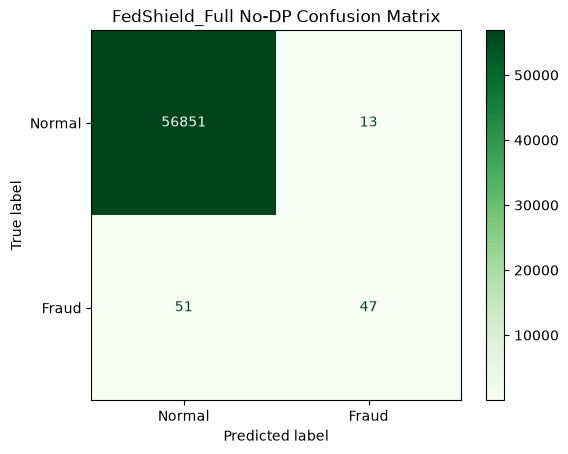

In [17]:
auc_fedshieldfull1_nodp = run_nodp_experiment("FedShield_Full", 15)


========== STARTING NON-DP PHASE: FedShieldFull2 ==========
Round 01/15 | ROC-AUC: 0.0614 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.0815 | PR-AUC: 0.0009
Round 03/15 | ROC-AUC: 0.2022 | PR-AUC: 0.0010
Round 04/15 | ROC-AUC: 0.4964 | PR-AUC: 0.0734
Round 05/15 | ROC-AUC: 0.7541 | PR-AUC: 0.4521
Round 06/15 | ROC-AUC: 0.8347 | PR-AUC: 0.5583
Round 07/15 | ROC-AUC: 0.8604 | PR-AUC: 0.6136
Round 08/15 | ROC-AUC: 0.8729 | PR-AUC: 0.6300
Round 09/15 | ROC-AUC: 0.8804 | PR-AUC: 0.6431
Round 10/15 | ROC-AUC: 0.8868 | PR-AUC: 0.6547
Round 11/15 | ROC-AUC: 0.8930 | PR-AUC: 0.6614
Round 12/15 | ROC-AUC: 0.8993 | PR-AUC: 0.6610
Round 13/15 | ROC-AUC: 0.9053 | PR-AUC: 0.6610
Round 14/15 | ROC-AUC: 0.9109 | PR-AUC: 0.6616
Round 15/15 | ROC-AUC: 0.9158 | PR-AUC: 0.6620

✅ FINAL FedShieldFull2 NO-DP RESULTS -> ROC-AUC: 0.9158 | PR-AUC: 0.6620 | Acc: 0.9989 | Fraud Prec: 0.7869 | Fraud Rec: 0.4898

--- FedShieldFull2 (No-DP) Classification Report ---
              precision    recall  f1-score   suppo

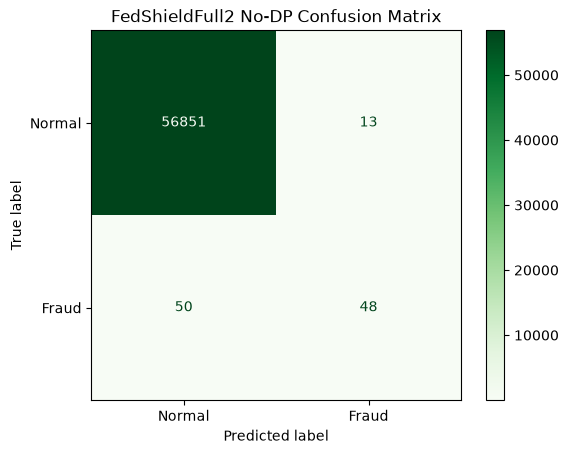

In [18]:
auc_fedshieldfull2_nodp = run_nodp_experiment("FedShieldFull2", 15)

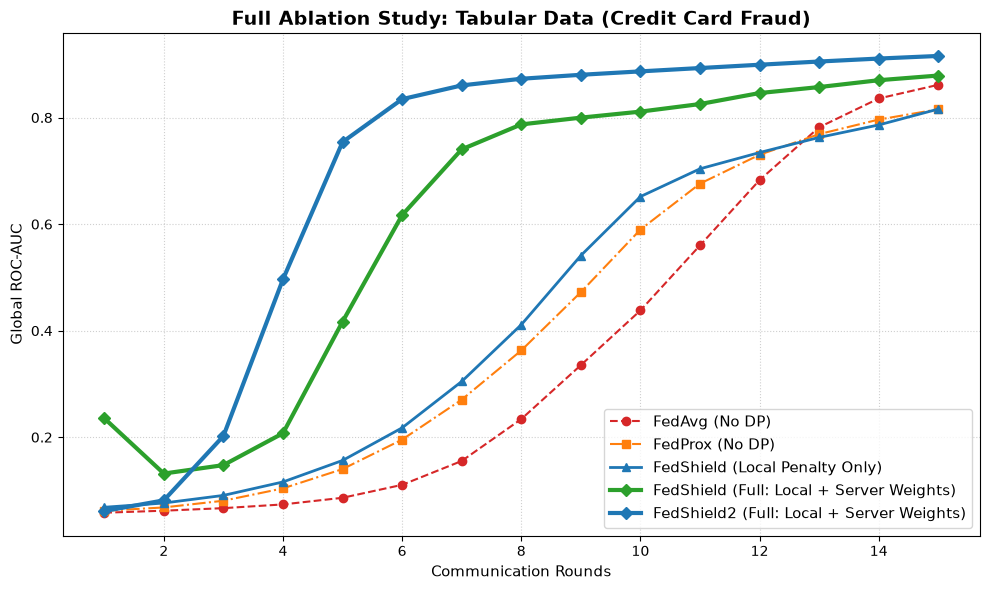

In [20]:
# ==============================================================================
# CELL 4: PLOT ABLATION RESULTS
# ==============================================================================
# Plot the 4-step Ablation Study
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, auc_fedavg_nodp, marker='o', linestyle='--', color='tab:red', label='FedAvg (No DP)')
plt.plot(rounds_range, auc_fedprox_nodp, marker='s', linestyle='-.', color='tab:orange', label='FedProx (No DP)')
plt.plot(rounds_range, auc_fedshield_nodp, marker='^', linestyle='-', color='tab:blue', linewidth=2, label='FedShield (Local Penalty Only)')
plt.plot(rounds_range, auc_fedshieldfull1_nodp, marker='D', linestyle='-', color='tab:green', linewidth=3, label='FedShield (Full: Local + Server Weights)')
plt.plot(rounds_range, auc_fedshieldfull2_nodp, marker='D', linestyle='-', color='tab:blue', linewidth=3, label='FedShield2 (Full: Local + Server Weights)')

plt.title("Full Ablation Study: Tabular Data (Credit Card Fraud)", fontsize=14, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global ROC-AUC", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()